**Step 1: Environment Setup and Dataset Verification**

In [10]:
import os
import sys
import pandas as pd
import torch

# Step 1.1: Check Python and library versions
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("PyTorch version:", torch.__version__)

# Step 1.2: Check GPU availability
print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

# Step 1.3: Verify dataset files
DATA_DIR = "/"

dataset_files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

print("\nDataset File Verification:")

for filename in dataset_files:
    filepath = os.path.join(DATA_DIR, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)
        print(f"FOUND: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {filename}")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Pandas version: 2.2.3
PyTorch version: 2.11.0+cu130

GPU Available: True
GPU Name: Tesla T4

Dataset File Verification:
FOUND: UNSW-NB15_1.csv (161.15 MB)
FOUND: UNSW-NB15_2.csv (157.57 MB)
FOUND: UNSW-NB15_3.csv (147.43 MB)
FOUND: UNSW-NB15_4.csv (93.07 MB)


**Step 2: Dataset Schema Identification**

In [11]:
import pandas as pd

columns = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm", "attack_cat", "label"
]

# Read only five rows for verification
df_sample = pd.read_csv(
    "/UNSW-NB15_1.csv",
    header=None,
    names=columns,
    nrows=5
)

print("Dataset shape:", df_sample.shape)
print("\nNumber of columns:", len(df_sample.columns))
print("\nColumn names:")
print(df_sample.columns.tolist())

display(df_sample)

Dataset shape: (5, 49)

Number of columns: 49

Column names:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


**Step 3: Count Records in the Four Dataset Files**

In [12]:
import os
import pandas as pd

dataset_files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

total_rows = 0

for filepath in dataset_files:
    row_count = 0

    for chunk in pd.read_csv(
        filepath,
        header=None,
        usecols=[0],
        chunksize=100_000
    ):
        row_count += len(chunk)

    print(f"{os.path.basename(filepath)}: {row_count:,} rows")
    total_rows += row_count

print("\nTotal records:", f"{total_rows:,}")

UNSW-NB15_1.csv: 700,001 rows
UNSW-NB15_2.csv: 700,001 rows
UNSW-NB15_3.csv: 700,001 rows
UNSW-NB15_4.csv: 440,044 rows

Total records: 2,540,047


**Step 4: Analysis of Attack-Category Distribution**

In [13]:
import pandas as pd
from collections import Counter

dataset_files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

attack_counts = Counter()

for filepath in dataset_files:
    print("Processing:", filepath)

    for chunk in pd.read_csv(
        filepath,
        header=None,
        usecols=[47],
        chunksize=100_000
    ):
        categories = (
            chunk.iloc[:, 0]
            .fillna("Normal")
            .astype(str)
            .str.strip()
            .replace("", "Normal")
        )

        attack_counts.update(
            categories.value_counts().to_dict()
        )

results = pd.DataFrame(
    list(attack_counts.items()),
    columns=["Attack Category", "Number of Records"]
)

results = results.sort_values(
    "Number of Records",
    ascending=False
).reset_index(drop=True)

print("\nAttack Category Distribution:")
display(results)

print("\nTotal records counted:", results["Number of Records"].sum())

Processing: /UNSW-NB15_1.csv


/tmp/ipykernel_471/4039484704.py:16: DtypeWarning: Columns (47) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Processing: /UNSW-NB15_2.csv


/tmp/ipykernel_471/4039484704.py:16: DtypeWarning: Columns (47) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Processing: /UNSW-NB15_3.csv
Processing: /UNSW-NB15_4.csv

Attack Category Distribution:


,Attack Category,Number of Records
0,Normal,2218764
1,Generic,215481
2,Exploits,44525
3,Fuzzers,24246
4,DoS,16353
5,Reconnaissance,13987
6,Analysis,2677
7,Backdoor,1795
8,Shellcode,1511
9,Backdoors,534



Total records counted: 2540047


**Step 5: Check label consistency and duplicate records**

In [14]:
import pandas as pd
from collections import Counter

files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

normal_with_attack = 0
attack_without_category = 0
label_counts = Counter()
category_counts = Counter()
duplicate_rows_within_files = {}

for filepath in files:
    print("Processing:", filepath)

    file_rows = 0
    file_duplicates = 0
    seen_rows = set()

    for chunk in pd.read_csv(
        filepath,
        header=None,
        usecols=[47, 48],
        chunksize=100_000,
        low_memory=False
    ):
        chunk.columns = ["attack_cat", "label"]

        categories = (
            chunk["attack_cat"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        labels = pd.to_numeric(
            chunk["label"], errors="coerce"
        )

        normal_with_attack += (
            (labels == 0) & (categories != "")
        ).sum()

        attack_without_category += (
            (labels == 1) & (categories == "")
        ).sum()

        label_counts.update(
            labels.value_counts().to_dict()
        )

        category_counts.update(
            categories.replace("", "Normal").value_counts().to_dict()
        )

        file_rows += len(chunk)

        # Count duplicate label/category pairs as a preliminary check
        pairs = list(zip(categories, labels))
        file_duplicates += len(pairs) - len(set(pairs))

    duplicate_rows_within_files[filepath] = file_duplicates

print("\nLabel counts:", label_counts)
print("Category counts:", category_counts)
print("Normal records with an attack category:", normal_with_attack)
print("Attack records without a category:", attack_without_category)

print("\nDuplicate label/category pairs within each file:")
for filepath, count in duplicate_rows_within_files.items():
    print(filepath, ":", count)

Processing: /UNSW-NB15_1.csv
Processing: /UNSW-NB15_2.csv
Processing: /UNSW-NB15_3.csv
Processing: /UNSW-NB15_4.csv

Label counts: Counter({0: 2218764, 1: 321283})
Category counts: Counter({'Normal': 2218764, 'Generic': 215481, 'Exploits': 44525, 'Fuzzers': 24246, 'DoS': 16353, 'Reconnaissance': 13987, 'Analysis': 2677, 'Backdoor': 1795, 'Shellcode': 1511, 'Backdoors': 534, 'Worms': 174})
Normal records with an attack category: 0
Attack records without a category: 0

Duplicate label/category pairs within each file:
/UNSW-NB15_1.csv : 699975
/UNSW-NB15_2.csv : 699957
/UNSW-NB15_3.csv : 699930
/UNSW-NB15_4.csv : 439994


**Step 6: Check actual duplicate network records**

In [15]:
import pandas as pd
import numpy as np

files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

seen_hashes = set()
total_rows = 0
duplicate_rows = 0

for filepath in files:
    print("Checking:", filepath)

    for chunk in pd.read_csv(
        filepath,
        header=None,
        chunksize=50_000,
        low_memory=False
    ):
        # Hash each complete row across all 49 columns
        hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).to_numpy(dtype=np.uint64)

        total_rows += len(hashes)

        # Count repeated row hashes, including duplicates
        # that appeared in earlier chunks or files.
        for value in hashes:
            key = int(value)
            if key in seen_hashes:
                duplicate_rows += 1
            else:
                seen_hashes.add(key)

print("\nTotal rows checked:", total_rows)
print("Repeated full-row records:", duplicate_rows)
print("Unique row hashes:", len(seen_hashes))

Checking: /UNSW-NB15_1.csv
Checking: /UNSW-NB15_2.csv
Checking: /UNSW-NB15_3.csv
Checking: /UNSW-NB15_4.csv

Total rows checked: 2540047
Repeated full-row records: 480629
Unique row hashes: 2059418


**Step 7: Analyze Duplicate Records by Attack**

In [16]:
import pandas as pd
from collections import defaultdict

files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

seen_hashes = set()
category_total = defaultdict(int)
category_duplicates = defaultdict(int)

for filepath in files:
    print("Processing:", filepath)

    for chunk in pd.read_csv(
        filepath,
        header=None,
        usecols=list(range(49)),
        chunksize=50_000,
        low_memory=False
    ):
        categories = (
            chunk[47]
            .fillna("Normal")
            .astype(str)
            .str.strip()
            .replace("", "Normal")
        )

        hashes = pd.util.hash_pandas_object(
            chunk, index=False
        ).to_numpy()

        for category, row_hash in zip(categories, hashes):
            category_total[category] += 1
            key = int(row_hash)

            if key in seen_hashes:
                category_duplicates[category] += 1
            else:
                seen_hashes.add(key)

summary = pd.DataFrame([
    {
        "Attack Category": category,
        "Total Records": total,
        "Repeated Records": category_duplicates[category]
    }
    for category, total in category_total.items()
])

summary["Repeated Percentage"] = (
    100 * summary["Repeated Records"] / summary["Total Records"]
)

summary = summary.sort_values(
    "Repeated Records", ascending=False
).reset_index(drop=True)

display(summary)

Processing: /UNSW-NB15_1.csv
Processing: /UNSW-NB15_2.csv
Processing: /UNSW-NB15_3.csv
Processing: /UNSW-NB15_4.csv


,Attack Category,Total Records,Repeated Records,Repeated Percentage
0,Normal,2218764,258989,11.672670
1,Generic,215481,190103,88.222628
2,Exploits,44525,16926,38.014599
3,DoS,16353,10688,65.358038
4,Fuzzers,24246,2451,10.108884
5,Reconnaissance,13987,630,4.504182
6,Analysis,2677,493,18.416137
7,Backdoors,534,235,44.007491
8,Backdoor,1795,111,6.183844
9,Worms,174,3,1.724138


**Step 8: Verify Label Consistency and Identify Missing Values**

In [17]:
import pandas as pd
import numpy as np

files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

total_missing = np.zeros(49, dtype=np.int64)
normal_with_attack = 0
attack_without_category = 0
total_rows = 0

for filepath in files:
    print("Checking:", filepath)

    for chunk in pd.read_csv(
        filepath,
        header=None,
        chunksize=50_000,
        low_memory=False
    ):
        total_rows += len(chunk)

        # Count missing values in each column
        total_missing += chunk.isna().sum().to_numpy()

        # Check attack-category and binary-label consistency
        categories = (
            chunk[47]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        labels = pd.to_numeric(
            chunk[48], errors="coerce"
        )

        normal_with_attack += int(
            ((labels == 0) & (categories != "")).sum()
        )

        attack_without_category += int(
            ((labels == 1) & (categories == "")).sum()
        )

print("\nTotal records checked:", total_rows)

print("\nMissing values by column:")
for index, count in enumerate(total_missing):
    print(f"Column {index}: {count}")

print("\nNormal records with attack categories:", normal_with_attack)
print("Attack records without categories:", attack_without_category)

Checking: /UNSW-NB15_1.csv
Checking: /UNSW-NB15_2.csv
Checking: /UNSW-NB15_3.csv
Checking: /UNSW-NB15_4.csv

Total records checked: 2540047

Missing values by column:
Column 0: 0
Column 1: 0
Column 2: 0
Column 3: 0
Column 4: 0
Column 5: 0
Column 6: 0
Column 7: 0
Column 8: 0
Column 9: 0
Column 10: 0
Column 11: 0
Column 12: 0
Column 13: 0
Column 14: 0
Column 15: 0
Column 16: 0
Column 17: 0
Column 18: 0
Column 19: 0
Column 20: 0
Column 21: 0
Column 22: 0
Column 23: 0
Column 24: 0
Column 25: 0
Column 26: 0
Column 27: 0
Column 28: 0
Column 29: 0
Column 30: 0
Column 31: 0
Column 32: 0
Column 33: 0
Column 34: 0
Column 35: 0
Column 36: 0
Column 37: 1348145
Column 38: 1429879
Column 39: 0
Column 40: 0
Column 41: 0
Column 42: 0
Column 43: 0
Column 44: 0
Column 45: 0
Column 46: 0
Column 47: 2218764
Column 48: 0

Normal records with attack categories: 0
Attack records without categories: 0


**Step 9: Prepare the Dataset Schema and Verify Feature Types**

In [18]:
import pandas as pd

columns = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm", "attack_cat", "label"
]

sample_frames = []

for filepath in [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]:
    sample = pd.read_csv(
        filepath,
        header=None,
        names=columns,
        nrows=1000,
        low_memory=False
    )
    sample_frames.append(sample)

sample_df = pd.concat(sample_frames, ignore_index=True)

print("Sample shape:", sample_df.shape)

print("\nCategorical features:")
print(sample_df.select_dtypes(include=["object"]).columns.tolist())

print("\nNumerical features:")
print(sample_df.select_dtypes(include=["number"]).columns.tolist())

print("\nTarget columns:")
print(["attack_cat", "label"])

print("\nSample data:")
display(sample_df.head())

Sample shape: (4000, 49)

Categorical features:
['srcip', 'dstip', 'dsport', 'proto', 'state', 'service', 'ct_ftp_cmd', 'attack_cat']

Numerical features:
['sport', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'label']

Target columns:
['attack_cat', 'label']

Sample data:


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


**Step 10: Prepare the Full Working Dataset**

In [20]:

import pandas as pd
import os

# Paths of the four original dataset files
files = [
    "/UNSW-NB15_1.csv",
    "/UNSW-NB15_2.csv",
    "/UNSW-NB15_3.csv",
    "/UNSW-NB15_4.csv"
]

# Column names
columns = [
    "srcip", "sport", "dstip", "dsport", "proto", "state",
    "dur", "sbytes", "dbytes", "sttl", "dttl", "sloss",
    "dloss", "service", "Sload", "Dload", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "smeansz", "dmeansz",
    "trans_depth", "res_bdy_len", "Sjit", "Djit", "Stime",
    "Ltime", "Sintpkt", "Dintpkt", "tcprtt", "synack",
    "ackdat", "is_sm_ips_ports", "ct_state_ttl",
    "ct_flw_http_mthd", "is_ftp_login", "ct_ftp_cmd",
    "ct_srv_src", "ct_srv_dst", "ct_dst_ltm", "ct_src_ltm",
    "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm", "attack_cat", "label"
]

output_file = "/UNSW_NB15_working.csv"

# Remove an incomplete output from an earlier attempt, if present
if os.path.exists(output_file):
    os.remove(output_file)

total_rows = 0

# Process each file in chunks to reduce memory usage
for file_index, file_path in enumerate(files):
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Dataset file not found: {file_path}")

    file_rows = 0

    for chunk in pd.read_csv(
        file_path,
        header=None,
        names=columns,
        chunksize=100_000,
        low_memory=False
    ):
        chunk.to_csv(
            output_file,
            mode="a",
            index=False,
            header=(total_rows == 0)
        )

        rows_written = len(chunk)
        total_rows += rows_written
        file_rows += rows_written

    print(f"File {file_index + 1} completed: {file_rows:,} rows")

print("\nWorking dataset created successfully.")
print(f"Total rows: {total_rows:,}")
print(f"Saved at: {output_file}")
print(f"File size: {os.path.getsize(output_file) / (1024**2):.2f} MB")


File 1 completed: 700,001 rows
File 2 completed: 700,001 rows
File 3 completed: 700,001 rows
File 4 completed: 440,044 rows

Working dataset created successfully.
Total rows: 2,540,047
Saved at: /UNSW_NB15_working.csv
File size: 569.77 MB


**Step 11: Verify the Working Dataset**

In [21]:

import pandas as pd
import os

file_path = "/UNSW_NB15_working.csv"

# Read only a small sample first
sample = pd.read_csv(file_path, nrows=5)

print("File exists:", os.path.exists(file_path))
print("File size (MB):", round(os.path.getsize(file_path) / (1024**2), 2))
print("Number of columns:", len(sample.columns))
print("\nColumn names:")
print(sample.columns.tolist())

print("\nFirst 5 records:")
display(sample)

# Count records without loading the entire dataset into memory
total_rows = 0

for chunk in pd.read_csv(file_path, chunksize=100_000):
    total_rows += len(chunk)

print("\nTotal records verified:", f"{total_rows:,}")


File exists: True
File size (MB): 569.77
Number of columns: 49

Column names:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label']

First 5 records:


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


/tmp/ipykernel_471/688097817.py:21: DtypeWarning: Columns (1,3) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
/tmp/ipykernel_471/688097817.py:21: DtypeWarning: Columns (1,3,47) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
/tmp/ipykernel_471/688097817.py:21: DtypeWarning: Columns (3,39,47) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
/tmp/ipykernel_471/688097817.py:21: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
/tmp/ipykernel_471/688097817.py:21: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, chunksize=100_000):
/tmp/ipykernel_47


Total records verified: 2,540,047


**Step 12: Inspect Missing Values and Data Types**

In [22]:

import pandas as pd

file_path = "/UNSW_NB15_working.csv"

missing_counts = None
total_rows = 0

for chunk in pd.read_csv(
    file_path,
    chunksize=100_000,
    low_memory=False
):
    chunk_missing = chunk.isna().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

    total_rows += len(chunk)

print("Total records checked:", f"{total_rows:,}")
print("\nColumns containing missing values:")

missing_summary = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

if len(missing_summary) > 0:
    display(missing_summary.to_frame(name="Missing Values"))
else:
    print("No missing values found.")

print("\nMissing-value percentages:")
if len(missing_summary) > 0:
    display(
        (missing_summary / total_rows * 100)
        .round(2)
        .to_frame(name="Missing Percentage")
    )


Total records checked: 2,540,047

Columns containing missing values:


,Missing Values
attack_cat,2218764
is_ftp_login,1429879
ct_flw_http_mthd,1348145



Missing-value percentages:


,Missing Percentage
attack_cat,87.35
is_ftp_login,56.29
ct_flw_http_mthd,53.08


**Step 13: Handle Missing Values**

In [23]:

import pandas as pd
import os

input_file = "/UNSW_NB15_working.csv"
output_file = "/UNSW_NB15_cleaned.csv"

if os.path.exists(output_file):
    os.remove(output_file)

total_rows = 0
remaining_missing = None

for chunk in pd.read_csv(
    input_file,
    chunksize=100_000,
    low_memory=False
):
    # Standardize attack category labels
    chunk["attack_cat"] = chunk["attack_cat"].fillna(
        chunk["label"].map({0: "Normal", 1: "Unknown"})
    )

    # Provisional missing-value treatment
    chunk["ct_flw_http_mthd"] = chunk["ct_flw_http_mthd"].fillna(0)
    chunk["is_ftp_login"] = chunk["is_ftp_login"].fillna(0)

    # Write cleaned records incrementally
    chunk.to_csv(
        output_file,
        mode="a",
        index=False,
        header=(total_rows == 0)
    )

    missing = chunk.isna().sum()
    if remaining_missing is None:
        remaining_missing = missing
    else:
        remaining_missing += missing

    total_rows += len(chunk)

print("Cleaning completed.")
print("Total records:", f"{total_rows:,}")
print("Output file:", output_file)
print("File size (MB):", round(os.path.getsize(output_file) / (1024**2), 2))

print("\nColumns still containing missing values:")
print(remaining_missing[remaining_missing > 0])


Cleaning completed.
Total records: 2,540,047
Output file: /UNSW_NB15_cleaned.csv
File size (MB): 590.42

Columns still containing missing values:
Series([], dtype: int64)


**Step 14: Verify the Target Labels and Attack Categories**

In [24]:

import pandas as pd

file_path = "/UNSW_NB15_cleaned.csv"

label_counts = {}
category_counts = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=100_000,
    low_memory=False
):
    # Count binary target labels
    for label, count in chunk["label"].value_counts().items():
        label_counts[label] = label_counts.get(label, 0) + int(count)

    # Count attack categories
    for category, count in chunk["attack_cat"].value_counts().items():
        category_counts[category] = (
            category_counts.get(category, 0) + int(count)
        )

print("Binary Label Distribution:")
display(
    pd.DataFrame(
        sorted(label_counts.items()),
        columns=["Label", "Record Count"]
    )
)

print("\nAttack Category Distribution:")
category_df = pd.DataFrame(
    category_counts.items(),
    columns=["Attack Category", "Record Count"]
).sort_values("Record Count", ascending=False).reset_index(drop=True)

category_df["Percentage"] = (
    category_df["Record Count"] / sum(category_counts.values()) * 100
).round(3)

display(category_df)

print("\nTotal records:", f"{sum(label_counts.values()):,}")
print("Number of attack categories:", len(category_counts))


Binary Label Distribution:


,Label,Record Count
0,0,2218764
1,1,321283



Attack Category Distribution:


,Attack Category,Record Count,Percentage
0,Normal,2218764,87.351
1,Generic,215481,8.483
2,Exploits,44525,1.753
3,Fuzzers,19195,0.756
4,DoS,16353,0.644
5,Reconnaissance,12228,0.481
6,Fuzzers,5051,0.199
7,Analysis,2677,0.105
8,Backdoor,1795,0.071
9,Reconnaissance,1759,0.069



Total records: 2,540,047
Number of attack categories: 14


**Step 15: Clean Attack Category Names**

In [25]:

import pandas as pd

file_path = "/UNSW_NB15_cleaned.csv"

category_counts = {}

for chunk in pd.read_csv(
    file_path,
    chunksize=100_000,
    low_memory=False
):
    # Remove extra spaces around category names
    chunk["attack_cat"] = chunk["attack_cat"].astype(str).str.strip()

    counts = chunk["attack_cat"].value_counts()

    for category, count in counts.items():
        category_counts[category] = (
            category_counts.get(category, 0) + int(count)
        )

print("Attack categories after whitespace cleanup:\n")

for category, count in sorted(
    category_counts.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{category}: {count:,}")

print("\nTotal unique categories:", len(category_counts))


Attack categories after whitespace cleanup:

Normal: 2,218,764
Generic: 215,481
Exploits: 44,525
Fuzzers: 24,246
DoS: 16,353
Reconnaissance: 13,987
Analysis: 2,677
Backdoor: 1,795
Shellcode: 1,511
Backdoors: 534
Worms: 174

Total unique categories: 11


**Step 16: Prepare the Final Attack Categories**

In [26]:

import pandas as pd
import os

input_file = "/UNSW_NB15_cleaned.csv"
output_file = "/UNSW_NB15_preprocessed.csv"

if os.path.exists(output_file):
    os.remove(output_file)

total_rows = 0

for chunk in pd.read_csv(
    input_file,
    chunksize=100_000,
    low_memory=False
):
    # Standardize category formatting
    chunk["attack_cat"] = chunk["attack_cat"].astype(str).str.strip()

    chunk.to_csv(
        output_file,
        mode="a",
        index=False,
        header=(total_rows == 0)
    )

    total_rows += len(chunk)

print("Preprocessing completed.")
print("Total records:", f"{total_rows:,}")
print("Saved to:", output_file)
print("File size (MB):", round(os.path.getsize(output_file) / (1024**2), 2))


Preprocessing completed.
Total records: 2,540,047
Saved to: /UNSW_NB15_preprocessed.csv
File size (MB): 590.35


**Step 17: Prepare Features and Target**

In [27]:

import pandas as pd
import os

input_file = "/UNSW_NB15_preprocessed.csv"
output_file = "/UNSW_NB15_model_data.csv"

# Columns excluded from the initial baseline features
drop_columns = [
    "srcip", "dstip", "Stime", "Ltime", "label"
]

if os.path.exists(output_file):
    os.remove(output_file)

total_rows = 0

for chunk in pd.read_csv(
    input_file,
    chunksize=100_000,
    low_memory=False
):
    # Keep attack category as the prediction target
    chunk = chunk.drop(columns=drop_columns)

    # Ensure the target is a clean string
    chunk["attack_cat"] = chunk["attack_cat"].astype(str).str.strip()

    chunk.to_csv(
        output_file,
        mode="a",
        index=False,
        header=(total_rows == 0)
    )

    total_rows += len(chunk)

print("Feature preparation completed.")
print("Records:", f"{total_rows:,}")
print("Input features:", len(pd.read_csv(output_file, nrows=1).columns) - 1)
print("Target column: attack_cat")
print("Saved to:", output_file)
print("File size (MB):", round(os.path.getsize(output_file) / (1024**2), 2))


Feature preparation completed.
Records: 2,540,047
Input features: 43
Target column: attack_cat
Saved to: /UNSW_NB15_model_data.csv
File size (MB): 470.03


**Step 18: Identify Categorical and Numerical Features**

In [28]:

import pandas as pd

file_path = "/UNSW_NB15_model_data.csv"

# Read a sample to inspect feature types without loading the full dataset
sample = pd.read_csv(
    file_path,
    nrows=20_000,
    low_memory=False
)

target_column = "attack_cat"

X_sample = sample.drop(columns=[target_column])

categorical_columns = X_sample.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X_sample.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Total input features:", len(X_sample.columns))

print("\nCategorical features:", len(categorical_columns))
print(categorical_columns)

print("\nNumerical features:", len(numerical_columns))
print(numerical_columns)

print("\nTarget categories in sample:")
print(sample[target_column].value_counts())


Total input features: 43

Categorical features: 4
['dsport', 'proto', 'state', 'service']

Numerical features: 39
['sport', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']

Target categories in sample:
attack_cat
Normal            18428
Fuzzers             724
Exploits            510
Reconnaissance      182
DoS                  68
Generic              59
Shellcode            23
Worms                 4
Backdoors             2
Name: count, dtype: int64


**Step 19: Create a Stratified Train-Test Split**

In [29]:

import pandas as pd
from sklearn.model_selection import train_test_split

file_path = "/UNSW_NB15_model_data.csv"

# Read target labels only to create the stratified split
target = pd.read_csv(
    file_path,
    usecols=["attack_cat"],
    low_memory=False
)["attack_cat"].astype(str).str.strip()

# Create row indices for train and test sets
indices = pd.Series(range(len(target)))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("Total records:", f"{len(target):,}")
print("Training records:", f"{len(train_idx):,}")
print("Testing records:", f"{len(test_idx):,}")

print("\nTraining class counts:")
display(target.iloc[train_idx].value_counts().to_frame("Training Records"))

print("\nTesting class counts:")
display(target.iloc[test_idx].value_counts().to_frame("Testing Records"))

# Save indices for later processing without rewriting the full dataset
pd.DataFrame({"row_index": train_idx}).to_csv(
    "/train_indices.csv", index=False
)
pd.DataFrame({"row_index": test_idx}).to_csv(
    "/test_indices.csv", index=False
)

print("\nSaved train and test row indices.")


Total records: 2,540,047
Training records: 2,032,037
Testing records: 508,010

Training class counts:


,Training Records
attack_cat,
Normal,1775011
Generic,172385
Exploits,35620
Fuzzers,19397
DoS,13082
Reconnaissance,11189
Analysis,2142
Backdoor,1436
Shellcode,1209



Testing class counts:


,Testing Records
attack_cat,
Normal,443753
Generic,43096
Exploits,8905
Fuzzers,4849
DoS,3271
Reconnaissance,2798
Analysis,535
Backdoor,359
Shellcode,302



Saved train and test row indices.


**Step 20: Prepare the Baseline Model Pipeline**

In [30]:

import pandas as pd

data_file = "/UNSW_NB15_model_data.csv"

# Load the row indices created in Step 19
train_idx = pd.read_csv("/train_indices.csv")["row_index"].to_numpy()
test_idx = pd.read_csv("/test_indices.csv")["row_index"].to_numpy()

# Read the dataset in chunks and retain the selected rows
train_parts = []
test_parts = []

train_set = set(train_idx)
test_set = set(test_idx)

offset = 0

for chunk in pd.read_csv(
    data_file,
    chunksize=100_000,
    low_memory=False
):
    row_numbers = range(offset, offset + len(chunk))

    train_positions = [
        i - offset for i in row_numbers if i in train_set
    ]
    test_positions = [
        i - offset for i in row_numbers if i in test_set
    ]

    if train_positions:
        train_parts.append(chunk.iloc[train_positions])

    if test_positions:
        test_parts.append(chunk.iloc[test_positions])

    offset += len(chunk)

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

# Separate features and target
X_train = train_df.drop(columns=["attack_cat"])
y_train = train_df["attack_cat"]

X_test = test_df.drop(columns=["attack_cat"])
y_test = test_df["attack_cat"]

# Identify categorical fields explicitly
categorical_features = ["sport", "dsport", "proto", "state", "service"]
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Keep categorical fields consistent
for col in categorical_features:
    X_train[col] = X_train[col].fillna("Unknown").astype(str)
    X_test[col] = X_test[col].fillna("Unknown").astype(str)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("Categorical features:", categorical_features)
print("Numerical feature count:", len(numerical_features))


Training feature shape: (2032037, 43)
Testing feature shape: (508010, 43)
Training target shape: (2032037,)
Testing target shape: (508010,)
Categorical features: ['sport', 'dsport', 'proto', 'state', 'service']
Numerical feature count: 38


**Step 21: Train the Baseline Random Forest**

In [32]:

import pandas as pd

categorical_features = ["sport", "dsport", "proto", "state", "service"]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Clean numerical columns in both training and testing data
for col in numerical_features:
    X_train[col] = pd.to_numeric(
        X_train[col].astype(str).str.strip().replace("", pd.NA),
        errors="coerce"
    )

    X_test[col] = pd.to_numeric(
        X_test[col].astype(str).str.strip().replace("", pd.NA),
        errors="coerce"
    )

print("Numerical columns cleaned.")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nRemaining missing values in numerical training features:",
      int(X_train[numerical_features].isna().sum().sum()))

print("Remaining missing values in numerical testing features:",
      int(X_test[numerical_features].isna().sum().sum()))


Numerical columns cleaned.
Training rows: 2032037
Testing rows: 508010

Remaining missing values in numerical training features: 1143814
Remaining missing values in numerical testing features: 286065


In [34]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
import time

# Use a reproducible 100,000-row training sample
sample_size = 100_000

X_train_sample = X_train.sample(
    n=sample_size,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

print("Training sample:", X_train_sample.shape)
print("Test set:", X_test.shape)

# Create a fresh copy of the existing pipeline
sample_model = clone(baseline_model)

start_time = time.time()

print("\nTraining Random Forest on 100,000 records...")
sample_model.fit(X_train_sample, y_train_sample)

print("\nTraining completed.")
print("Time taken:", round((time.time() - start_time) / 60, 2), "minutes")

# Evaluate on the existing untouched test set
y_pred_sample = sample_model.predict(X_test)

print("\nBaseline Sample Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_sample), 4))
print("Macro F1:", round(f1_score(
    y_test, y_pred_sample, average="macro", zero_division=0
), 4))
print("Weighted F1:", round(f1_score(
    y_test, y_pred_sample, average="weighted", zero_division=0
), 4))

Training sample: (100000, 43)
Test set: (508010, 43)

Training Random Forest on 100,000 records...

Training completed.
Time taken: 3.55 minutes

Baseline Sample Results
Accuracy: 0.9781
Macro F1: 0.447
Weighted F1: 0.977


**Step 23 — Check performance for each attack category**

In [35]:
from sklearn.metrics import classification_report

print("Baseline Random Forest: Per-Class Performance\n")

print(classification_report(
    y_test,
    y_pred_sample,
    zero_division=0,
    digits=4
))

Baseline Random Forest: Per-Class Performance

                precision    recall  f1-score   support

      Analysis     0.0452    0.0150    0.0225       535
      Backdoor     0.0545    0.0251    0.0344       359
     Backdoors     0.0923    0.0561    0.0698       107
           DoS     0.3204    0.2372    0.2726      3271
      Exploits     0.6141    0.7723    0.6841      8905
       Fuzzers     0.6241    0.4828    0.5444      4849
       Generic     0.9940    0.9776    0.9858     43096
        Normal     0.9939    0.9975    0.9957    443753
Reconnaissance     0.8581    0.7091    0.7765      2798
     Shellcode     0.7640    0.4073    0.5313       302
         Worms     0.0000    0.0000    0.0000        35

      accuracy                         0.9781    508010
     macro avg     0.4873    0.4254    0.4470    508010
  weighted avg     0.9766    0.9781    0.9770    508010



**Step 24 — Check minority-class counts in the training sample**

In [37]:
print("Attack category counts in the training sample:\n")

print(y_train_sample.value_counts().sort_values())

print("\nTotal training records:", len(y_train_sample))
print("Number of attack categories:", y_train_sample.nunique())

Attack category counts in the training sample:

attack_cat
Worms                 6
Backdoors            31
Shellcode            58
Backdoor             84
Analysis             94
Reconnaissance      545
DoS                 626
Fuzzers             979
Exploits           1813
Generic            8548
Normal            87216
Name: count, dtype: int64

Total training records: 100000
Number of attack categories: 11


**Step 25 — Install CTGAN**

In [38]:
%pip install ctgan

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.7/71.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 93.6 MB/s eta 0:00:00


**Step 26 — Verify CTGAN installation**

In [39]:
import ctgan
print("CTGAN installed successfully!")
print("CTGAN version:", ctgan.__version__)

CTGAN installed successfully!
CTGAN version: 0.12.1


**Step 27 — Prepare minority-class data for CTGAN**

In [40]:
minority_classes = [
    "Worms",
    "Backdoors",
    "Shellcode",
    "Backdoor",
    "Analysis"
]

minority_mask = y_train_sample.isin(minority_classes)

X_minority = X_train_sample.loc[minority_mask].copy()
y_minority = y_train_sample.loc[minority_mask].copy()

minority_data = X_minority.copy()
minority_data["attack_cat"] = y_minority

print("Minority-class dataset shape:", minority_data.shape)
print("\nRecords per minority category:")
print(minority_data["attack_cat"].value_counts())

Minority-class dataset shape: (273, 44)

Records per minority category:
attack_cat
Analysis     94
Backdoor     84
Shellcode    58
Backdoors    31
Worms         6
Name: count, dtype: int64


**Step 28 — Check the data types before CTGAN training**

In [41]:
print("Minority dataset shape:", minority_data.shape)

print("\nCategorical feature data types:")
print(minority_data[categorical_features].dtypes)

print("\nNumerical feature data types:")
print(minority_data[numerical_features].dtypes.value_counts())

print("\nMissing values:", minority_data.isna().sum().sum())

Minority dataset shape: (273, 44)

Categorical feature data types:
sport      object
dsport     object
proto      object
state      object
service    object
dtype: object

Numerical feature data types:
int64      25
float64    13
Name: count, dtype: int64

Missing values: 214


**Step 29 — Handle missing values in the minority dataset**

In [42]:
minority_data = minority_data.copy()

# Fill missing categorical values
for col in categorical_features:
    minority_data[col] = (
        minority_data[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

# Fill missing numerical values using column medians
for col in numerical_features:
    minority_data[col] = minority_data[col].fillna(
        minority_data[col].median()
    )

print("Remaining missing values:", minority_data.isna().sum().sum())
print("Dataset shape:", minority_data.shape)

print("\nRecords per attack category:")
print(minority_data["attack_cat"].value_counts())

Remaining missing values: 0
Dataset shape: (273, 44)

Records per attack category:
attack_cat
Analysis     94
Backdoor     84
Shellcode    58
Backdoors    31
Worms         6
Name: count, dtype: int64


**Step 30 — Prepare the data for CTGAN**

In [43]:
from ctgan import CTGAN

# CTGAN will learn from the feature columns and attack category
ctgan_data = minority_data.copy()

# Identify categorical columns, including the target label
discrete_columns = categorical_features + ["attack_cat"]

print("CTGAN input shape:", ctgan_data.shape)
print("\nDiscrete columns:")
print(discrete_columns)

print("\nAttack category counts:")
print(ctgan_data["attack_cat"].value_counts())

CTGAN input shape: (273, 44)

Discrete columns:
['sport', 'dsport', 'proto', 'state', 'service', 'attack_cat']

Attack category counts:
attack_cat
Analysis     94
Backdoor     84
Shellcode    58
Backdoors    31
Worms         6
Name: count, dtype: int64


**Step 31 — Train the CTGAN model**

In [44]:
from ctgan import CTGAN
import time

# Create the generator
ctgan_model = CTGAN(
    epochs=100,
    batch_size=50,
    verbose=True
)

start_time = time.time()

print("Training CTGAN on minority-class data...")

ctgan_model.fit(
    ctgan_data,
    discrete_columns=discrete_columns
)

elapsed = (time.time() - start_time) / 60

print("\nCTGAN training completed.")
print("Training time:", round(elapsed, 2), "minutes")

Training CTGAN on minority-class data...


Gen. (+00.00) | Discrim. (+00.00):   0%|          | 0/100 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Gen. (-01.04) | Discrim. (+01.09): 100%|██████████| 100/100 [00:27<00:00,  3.60it/s]


CTGAN training completed.
Training time: 0.66 minutes


**Step 32 — Generate synthetic minority-class records**

In [45]:
synthetic_data = ctgan_model.sample(500)

print("Synthetic dataset shape:", synthetic_data.shape)

print("\nGenerated attack category counts:")
print(synthetic_data["attack_cat"].value_counts())

print("\nFirst 5 synthetic records:")
display(synthetic_data.head())

Synthetic dataset shape: (500, 44)

Generated attack category counts:
attack_cat
Shellcode    147
Backdoor     135
Analysis     132
Backdoors     56
Worms         30
Name: count, dtype: int64

First 5 synthetic records:


,sport,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,...,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat
0,0,0,unas,REQ,1.427258,178,2314,179,4,0,...,-0.000867,0.003301,5,9,1,1,2,1,1,Analysis
1,0,39545,udp,CON,0.126531,915,514,258,228,1,...,-0.001387,0.002657,1,2,1,4,1,2,0,Backdoors
2,11473,4210,eigrp,REQ,-0.698767,710,1530,264,0,0,...,0.000440,-0.002114,3,3,6,0,1,2,0,Backdoor
3,24791,0,unas,FIN,0.164244,366,267,261,256,0,...,0.001158,0.000594,12,0,3,11,1,1,1,Analysis
4,32340,2633,tcp,INT,0.919093,165,228,266,-4,0,...,-0.000305,0.001769,7,1,2,-1,0,1,2,Backdoors


**Step 33 — Validate synthetic feature values**

In [46]:
import pandas as pd

print("Synthetic dataset shape:", synthetic_data.shape)

# Check for missing values
print("\nMissing values:", synthetic_data.isna().sum().sum())

# Check negative values in numerical features
negative_counts = (
    synthetic_data[numerical_features] < 0
).sum()

print("\nNumerical features containing negative values:")
print(negative_counts[negative_counts > 0].sort_values(ascending=False))

# Check whether generated categories match original training categories
for col in categorical_features:
    original_values = set(X_train_sample[col].astype(str).str.strip())
    generated_values = set(synthetic_data[col].astype(str).str.strip())

    unseen_values = generated_values - original_values

    print(f"\n{col}:")
    print("Unseen categorical values:", unseen_values)

# Check attack category distribution
print("\nSynthetic attack category counts:")
print(synthetic_data["attack_cat"].value_counts())

Synthetic dataset shape: (500, 44)

Missing values: 0

Numerical features containing negative values:
is_ftp_login        411
dtcpb               386
res_bdy_len         309
ct_flw_http_mthd    293
Dintpkt             284
tcprtt              282
sbytes              280
Sjit                248
dwin                187
dmeansz             182
Sintpkt             163
ct_ftp_cmd          158
Djit                143
stcpb               112
dur                 101
synack               86
ct_dst_src_ltm       82
ackdat               69
dbytes               66
ct_src_ltm           37
Dload                34
dttl                 34
swin                 33
Sload                23
Dpkts                16
ct_src_dport_ltm     10
sloss                 5
ct_srv_src            4
ct_dst_ltm            2
ct_state_ttl          1
dtype: int64

sport:
Unseen categorical values: set()

dsport:
Unseen categorical values: set()

proto:
Unseen categorical values: set()

state:
Unseen categorical values: set()


**Step 34 — Correct invalid synthetic numerical values**

In [47]:
synthetic_corrected = synthetic_data.copy()

# Clip numerical values to the observed training-sample ranges
for col in numerical_features:
    lower = X_train_sample[col].min()
    upper = X_train_sample[col].max()

    synthetic_corrected[col] = synthetic_corrected[col].clip(
        lower=lower,
        upper=upper
    )

# Binary features must contain only 0 or 1
for col in ["is_sm_ips_ports", "is_ftp_login"]:
    synthetic_corrected[col] = (
        synthetic_corrected[col].round().clip(0, 1).astype(int)
    )

# Count-like features must be non-negative integers
count_features = [
    "sbytes", "dbytes", "sloss", "dloss", "Spkts", "Dpkts",
    "swin", "dwin", "stcpb", "dtcpb", "trans_depth",
    "res_bdy_len", "ct_state_ttl", "ct_flw_http_mthd",
    "ct_ftp_cmd", "ct_srv_src", "ct_srv_dst", "ct_dst_ltm",
    "ct_src_ltm", "ct_src_dport_ltm", "ct_dst_sport_ltm",
    "ct_dst_src_ltm"
]

for col in count_features:
    synthetic_corrected[col] = (
        synthetic_corrected[col].clip(lower=0).round().astype("int64")
    )

print("Original synthetic shape:", synthetic_data.shape)
print("Corrected synthetic shape:", synthetic_corrected.shape)

print("\nMissing values:", synthetic_corrected.isna().sum().sum())

print("\nNegative values remaining in numerical features:")
negative_counts = (synthetic_corrected[numerical_features] < 0).sum()
print(negative_counts[negative_counts > 0])

print("\nBinary feature values:")
for col in ["is_sm_ips_ports", "is_ftp_login"]:
    print(col, sorted(synthetic_corrected[col].unique()))

Original synthetic shape: (500, 44)
Corrected synthetic shape: (500, 44)

Missing values: 0

Negative values remaining in numerical features:
Series([], dtype: int64)

Binary feature values:
is_sm_ips_ports [np.int64(0)]
is_ftp_login [np.int64(0)]


**Step 35 — Compare original and corrected feature values**

In [48]:
print("Original binary feature distributions:")

for col in ["is_sm_ips_ports", "is_ftp_login"]:
    print(f"\n{col}:")
    print(X_train_sample[col].value_counts(dropna=False))

print("\nCorrected synthetic binary feature distributions:")

for col in ["is_sm_ips_ports", "is_ftp_login"]:
    print(f"\n{col}:")
    print(synthetic_corrected[col].value_counts(dropna=False))

print("\nMean comparison for selected numerical features:")

check_features = ["dur", "sbytes", "dbytes", "sttl", "dttl"]

comparison = pd.DataFrame({
    "Original training sample mean": X_train_sample[check_features].mean(),
    "Synthetic before correction": synthetic_data[check_features].mean(),
    "Synthetic after correction": synthetic_corrected[check_features].mean()
})

display(comparison.round(3))

Original binary feature distributions:

is_sm_ips_ports:
is_sm_ips_ports
0    99855
1      145
Name: count, dtype: int64

is_ftp_login:
is_ftp_login
0.0    98331
1.0     1658
4.0       10
2.0        1
Name: count, dtype: int64

Corrected synthetic binary feature distributions:

is_sm_ips_ports:
is_sm_ips_ports
0    500
Name: count, dtype: int64

is_ftp_login:
is_ftp_login
0    500
Name: count, dtype: int64

Mean comparison for selected numerical features:


,Original training sample mean,Synthetic before correction,Synthetic after correction
dur,0.632,2.714,2.512
sbytes,4354.240,136.024,493.620
dbytes,36487.275,1042.830,1076.552
sttl,63.186,253.346,247.274
dttl,30.788,145.366,128.858


**Step 36 — Check original feature ranges and binary-feature encoding**

In [49]:
check_features = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "is_sm_ips_ports", "is_ftp_login"
]

print("Original training sample: feature ranges\n")

for col in check_features:
    print(f"\n{col}")
    print("Minimum:", X_train_sample[col].min())
    print("Maximum:", X_train_sample[col].max())
    print("Unique values (first 15):")
    print(sorted(X_train_sample[col].dropna().unique())[:15])

Original training sample: feature ranges


dur
Minimum: 0.0
Maximum: 59.998466
Unique values (first 15):
[np.float64(0.0), np.float64(1e-06), np.float64(2e-06), np.float64(3e-06), np.float64(4e-06), np.float64(5e-06), np.float64(6e-06), np.float64(7e-06), np.float64(8e-06), np.float64(9e-06), np.float64(1e-05), np.float64(1.1e-05), np.float64(1.2e-05), np.float64(1.3e-05), np.float64(1.4e-05)]

sbytes
Minimum: 24
Maximum: 7504458
Unique values (first 15):
[np.int64(24), np.int64(28), np.int64(46), np.int64(56), np.int64(60), np.int64(64), np.int64(65), np.int64(73), np.int64(75), np.int64(76), np.int64(78), np.int64(80), np.int64(81), np.int64(82), np.int64(84)]

dbytes
Minimum: 0
Maximum: 14655550
Unique values (first 15):
[np.int64(0), np.int64(28), np.int64(46), np.int64(52), np.int64(56), np.int64(81), np.int64(82), np.int64(84), np.int64(86), np.int64(89), np.int64(91), np.int64(92), np.int64(102), np.int64(104), np.int64(112)]

sttl
Minimum: 0
Maximum: 255
Unique values (first 15

**Step 37 — Check feature constraints in the synthetic data**

In [50]:
range_violations = []

for col in numerical_features:
    original_min = X_train_sample[col].min()
    original_max = X_train_sample[col].max()

    synthetic_min = synthetic_data[col].min()
    synthetic_max = synthetic_data[col].max()

    if synthetic_min < original_min or synthetic_max > original_max:
        range_violations.append({
            "Feature": col,
            "Original Min": original_min,
            "Original Max": original_max,
            "Synthetic Min": synthetic_min,
            "Synthetic Max": synthetic_max
        })

violations_df = pd.DataFrame(range_violations)

print("Number of features outside original ranges:",
      len(violations_df))

display(violations_df)

Number of features outside original ranges: 35


,Feature,Original Min,Original Max,Synthetic Min,Synthetic Max
0,dur,0.0,5.999847e+01,-3.409439e+00,9.346780e+01
1,sbytes,24.0,7.504458e+06,-7.085000e+03,1.145600e+04
2,dbytes,0.0,1.465555e+07,-1.427000e+03,4.184000e+03
3,sttl,0.0,2.550000e+02,4.400000e+01,2.670000e+02
4,dttl,0.0,2.540000e+02,-2.800000e+01,3.430000e+02
5,sloss,0.0,2.822000e+03,-1.000000e+00,6.000000e+00
6,Sload,0.0,4.256000e+09,-6.837774e+07,1.708385e+09
7,Dload,0.0,2.150615e+07,-2.006166e+03,4.232407e+04
8,Spkts,1.0,5.652000e+03,0.000000e+00,1.450000e+02
9,Dpkts,0.0,1.097400e+04,-1.000000e+00,6.000000e+01


**Step 38 — Check the minority data before retraining CTGAN**

In [51]:
print("Minority dataset shape:", minority_data.shape)

print("\nNumerical feature ranges in minority data:")

display(
    minority_data[numerical_features]
    .describe()
    .T[["min", "max", "mean", "std"]]
    .round(3)
)

print("\nRecords per attack category:")
print(minority_data["attack_cat"].value_counts())

print("\nUnique values per selected feature:")
for col in ["dur", "sbytes", "dbytes", "sttl", "dttl"]:
    print(col, ":", minority_data[col].nunique())

Minority dataset shape: (273, 44)

Numerical feature ranges in minority data:


,min,max,mean,std
dur,0.0,5.974500e+01,1.365000e+00,7.075000e+00
sbytes,60.0,7.848100e+04,1.078912e+03,5.388267e+03
dbytes,0.0,4.341800e+04,4.576780e+02,3.706500e+03
sttl,0.0,2.540000e+02,2.385490e+02,5.395800e+01
dttl,0.0,2.520000e+02,5.995600e+01,1.067100e+02
sloss,0.0,3.000000e+01,6.890000e-01,2.409000e+00
dloss,0.0,2.100000e+01,5.130000e-01,1.929000e+00
Sload,0.0,1.344000e+09,1.417712e+08,1.999719e+08
Dload,0.0,1.989208e+05,2.693083e+03,1.294210e+04
Spkts,1.0,1.060000e+02,6.802000e+00,1.414700e+01



Records per attack category:
attack_cat
Analysis     94
Backdoor     84
Shellcode    58
Backdoors    31
Worms         6
Name: count, dtype: int64

Unique values per selected feature:
dur : 94
sbytes : 94
dbytes : 34
sttl : 3
dttl : 3


**Step 39 — Prepare a larger minority dataset**

In [52]:
minority_classes = [
    "Worms",
    "Backdoors",
    "Shellcode",
    "Backdoor",
    "Analysis"
]

# Select minority classes from the complete training split
minority_mask_full = y_train.isin(minority_classes)

X_minority_full = X_train.loc[minority_mask_full].copy()
y_minority_full = y_train.loc[minority_mask_full].copy()

# Combine features and target
minority_data_full = X_minority_full.copy()
minority_data_full["attack_cat"] = y_minority_full

print("Larger minority dataset shape:", minority_data_full.shape)

print("\nRecords per attack category:")
print(minority_data_full["attack_cat"].value_counts())

print("\nTotal minority records:", len(minority_data_full))

Larger minority dataset shape: (5353, 44)

Records per attack category:
attack_cat
Analysis     2142
Backdoor     1436
Shellcode    1209
Backdoors     427
Worms         139
Name: count, dtype: int64

Total minority records: 5353


**Step 40 — Prepare the larger dataset for CTGAN**

In [53]:
ctgan_data_full = minority_data_full.copy()

# Clean categorical columns
for col in categorical_features:
    ctgan_data_full[col] = (
        ctgan_data_full[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .replace("", "Unknown")
    )

# Clean the target column
ctgan_data_full["attack_cat"] = (
    ctgan_data_full["attack_cat"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# Convert numerical columns and fill missing values with their medians
for col in numerical_features:
    ctgan_data_full[col] = pd.to_numeric(
        ctgan_data_full[col], errors="coerce"
    )

    median_value = ctgan_data_full[col].median()

    if pd.isna(median_value):
        median_value = 0

    ctgan_data_full[col] = (
        ctgan_data_full[col].fillna(median_value)
    )

# Define categorical columns for CTGAN
discrete_columns_full = categorical_features + ["attack_cat"]

print("Dataset shape:", ctgan_data_full.shape)
print("Total missing values:", ctgan_data_full.isna().sum().sum())

print("\nClass distribution:")
print(ctgan_data_full["attack_cat"].value_counts())

print("\nCategorical columns:", discrete_columns_full)

Dataset shape: (5353, 44)
Total missing values: 0

Class distribution:
attack_cat
Analysis     2142
Backdoor     1436
Shellcode    1209
Backdoors     427
Worms         139
Name: count, dtype: int64

Categorical columns: ['sport', 'dsport', 'proto', 'state', 'service', 'attack_cat']


**Step 41 — Retrain CTGAN using the larger dataset**

In [54]:
from ctgan import CTGAN
import time

ctgan_model_full = CTGAN(
    epochs=100,
    batch_size=100,
    verbose=True
)

start_time = time.time()

ctgan_model_full.fit(
    ctgan_data_full,
    discrete_columns=discrete_columns_full
)

training_time = (time.time() - start_time) / 60

print(f"\nCTGAN training completed in {training_time:.2f} minutes.")

Gen. (+03.05) | Discrim. (-00.32): 100%|██████████| 100/100 [06:14<00:00,  3.74s/it]


CTGAN training completed in 6.83 minutes.


**Step 42 — Generate synthetic minority records**

In [55]:
synthetic_data_full = ctgan_model_full.sample(5000)

print("Synthetic dataset shape:", synthetic_data_full.shape)

print("\nSynthetic records per attack category:")
print(synthetic_data_full["attack_cat"].value_counts())

print("\nFirst five synthetic records:")
display(synthetic_data_full.head())

Synthetic dataset shape: (5000, 44)

Synthetic records per attack category:
attack_cat
Shellcode    2022
Backdoor     1428
Analysis      942
Backdoors     358
Worms         250
Name: count, dtype: int64

First five synthetic records:


,sport,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,...,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat
0,0,0,udp,INT,-0.388523,245,1113,252,-5,0,...,0.002070,-0.000417,1,2,2,1,2,1,1,Backdoor
1,45294,21,tcp,INT,-0.048558,353,623,254,-4,0,...,-0.001894,-0.000258,1,1,1,15,1,1,5,Analysis
2,10692,17809,tcp,FIN,0.297142,319,882,255,251,2,...,0.000582,-0.000243,1,2,2,2,1,6,1,Analysis
3,0,0,unas,INT,-0.410880,-682,285,253,-7,0,...,0.002157,0.000424,2,5,2,2,3,1,4,Backdoor
4,0,0,unas,INT,-0.406702,-292,218,251,-6,0,...,0.001571,0.000363,8,5,1,1,2,2,4,Backdoors


**Step 43 — Validate synthetic data quality**

In [56]:
# Identify numerical features
numeric_cols = numerical_features

# Count negative values in each numerical feature
negative_counts = (
    synthetic_data_full[numeric_cols]
    .lt(0)
    .sum()
    .sort_values(ascending=False)
)

print("Numerical features containing negative values:")
print(negative_counts[negative_counts > 0])

# Compare synthetic and real training ranges
print("\nRange comparison:")
for col in numeric_cols:
    real_min = X_minority_full[col].min()
    real_max = X_minority_full[col].max()
    synth_min = synthetic_data_full[col].min()
    synth_max = synthetic_data_full[col].max()

    if synth_min < real_min or synth_max > real_max:
        print(
            f"{col}: Real [{real_min}, {real_max}] | "
            f"Synthetic [{synth_min:.4f}, {synth_max:.4f}]"
        )

print("\nTotal negative numerical values:",
      int(synthetic_data_full[numeric_cols].lt(0).sum().sum()))

Numerical features containing negative values:
res_bdy_len         4132
Sjit                3096
dtcpb               3003
stcpb               2951
Sintpkt             2904
dur                 2745
dttl                2665
tcprtt              2298
Djit                2265
Dpkts               2122
dmeansz             2071
Sload               2041
ct_flw_http_mthd    2033
sbytes              1765
ct_ftp_cmd          1693
ackdat              1687
is_ftp_login        1033
Dload                949
swin                 386
dbytes               297
Dintpkt              223
synack               196
dwin                 163
dtype: int64

Range comparison:
dur: Real [0.0, 59.932392] | Synthetic [-1.2293, 66.4194]
sbytes: Real [60, 248562] | Synthetic [-765.0000, 24781.0000]
dbytes: Real [0, 915210] | Synthetic [-1113.0000, 2292.0000]
sttl: Real [0, 254] | Synthetic [40.0000, 257.0000]
dttl: Real [0, 252] | Synthetic [-8.0000, 264.0000]
Sload: Real [0.0, 2976000000.0] | Synthetic [-41772994.0116, 

**Step 44 — Correct the synthetic data carefully**

In [57]:
print("Binary or low-cardinality numerical features:")

for col in numerical_features:
    unique_count = X_minority_full[col].nunique()

    if unique_count <= 10:
        print(
            f"{col}: {unique_count} unique values | "
            f"Examples: {sorted(X_minority_full[col].dropna().unique())[:10]}"
        )

print("\nFeatures that are always zero in real minority data:")

for col in numerical_features:
    if (X_minority_full[col] == 0).all():
        print(col)

print("\nInteger-like feature examples:")
for col in ["sbytes", "dbytes", "sttl", "dttl", "Spkts", "Dpkts",
            "sloss", "dloss", "ct_state_ttl"]:
    print(f"{col}: {X_minority_full[col].head(5).tolist()}")

Binary or low-cardinality numerical features:
sttl: 3 unique values | Examples: [np.int64(0), np.int64(62), np.int64(254)]
dttl: 3 unique values | Examples: [np.int64(0), np.int64(60), np.int64(252)]
swin: 2 unique values | Examples: [np.int64(0), np.int64(255)]
dwin: 2 unique values | Examples: [np.int64(0), np.int64(255)]
trans_depth: 3 unique values | Examples: [np.int64(0), np.int64(1), np.int64(2)]
is_sm_ips_ports: 1 unique values | Examples: [np.int64(0)]
ct_state_ttl: 5 unique values | Examples: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(6)]
ct_flw_http_mthd: 10 unique values | Examples: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(4.0), np.float64(6.0), np.float64(9.0), np.float64(12.0), np.float64(16.0), np.float64(25.0), np.float64(30.0)]
is_ftp_login: 1 unique values | Examples: [np.float64(0.0)]
ct_ftp_cmd: 1 unique values | Examples: [np.float64(0.0)]

Features that are always zero in real minority data:
is_sm_ips_ports
is_ftp_login

In

**Step 45 — Apply basic feature constraints**

In [58]:
synthetic_candidate = synthetic_data_full.copy()

# Preserve observed values for low-cardinality features
restricted_values = [
    "sttl", "dttl", "swin", "dwin",
    "trans_depth", "ct_state_ttl", "ct_flw_http_mthd"
]

for col in restricted_values:
    allowed = X_minority_full[col].dropna().unique()
    values = synthetic_candidate[col].to_numpy()

    # Replace each generated value with its nearest observed value
    synthetic_candidate[col] = [
        allowed[np.abs(allowed - value).argmin()]
        for value in values
    ]

# Features that are constant in the real minority subset
constant_features = [
    col for col in numerical_features
    if X_minority_full[col].nunique() == 1
]

for col in constant_features:
    synthetic_candidate[col] = X_minority_full[col].iloc[0]

# Prevent negative values in the remaining nonnegative features
nonnegative_features = [
    col for col in numerical_features
    if X_minority_full[col].min() >= 0
    and col not in restricted_values
    and col not in constant_features
]

for col in nonnegative_features:
    synthetic_candidate[col] = synthetic_candidate[col].clip(lower=0)

print("Candidate dataset shape:", synthetic_candidate.shape)
print("Remaining negative numerical values:",
      int(synthetic_candidate[numerical_features].lt(0).sum().sum()))

print("\nConstant feature values:")
for col in constant_features:
    print(f"{col}: {synthetic_candidate[col].unique()}")

print("\nCandidate attack-category counts:")
print(synthetic_candidate["attack_cat"].value_counts())

Candidate dataset shape: (5000, 44)
Remaining negative numerical values: 0

Constant feature values:
is_sm_ips_ports: [0]
is_ftp_login: [0.]
ct_ftp_cmd: [0.]

Candidate attack-category counts:
attack_cat
Shellcode    2022
Backdoor     1428
Analysis      942
Backdoors     358
Worms         250
Name: count, dtype: int64


**Step 46 — Compare real and synthetic feature distributions**

In [59]:
comparison_features = [
    "dur", "sbytes", "dbytes", "sttl", "dttl",
    "Spkts", "Dpkts", "Sload", "Dload",
    "ct_state_ttl", "ct_srv_src", "ct_dst_src_ltm"
]

comparison = pd.DataFrame({
    "Real Mean": X_minority_full[comparison_features].mean(),
    "Synthetic Mean": synthetic_candidate[comparison_features].mean(),
    "Real Std": X_minority_full[comparison_features].std(),
    "Synthetic Std": synthetic_candidate[comparison_features].std()
})

comparison = comparison.round(3)

display(comparison)

,Real Mean,Synthetic Mean,Real Std,Synthetic Std
dur,1.500000e+00,1.606000e+00,7.546000e+00,7.267000e+00
sbytes,1.075717e+03,6.440820e+02,9.916434e+03,1.692262e+03
dbytes,1.992028e+03,9.594240e+02,3.071917e+04,5.604170e+02
sttl,2.349620e+02,2.437090e+02,5.792400e+01,4.324800e+01
dttl,6.905000e+01,9.945800e+01,1.118110e+02,1.219060e+02
Spkts,6.290000e+00,8.872000e+00,1.423200e+01,1.186200e+01
Dpkts,3.511000e+00,2.443000e+00,2.342900e+01,3.428000e+00
Sload,1.205331e+08,8.978226e+07,1.746344e+08,1.438344e+08
Dload,5.544775e+03,3.800156e+03,5.173635e+04,6.275403e+03
ct_state_ttl,1.750000e+00,1.644000e+00,6.490000e-01,9.150000e-01


**Step 47 — Compare baseline and augmented model performance**

In [60]:
# Combine the original training sample with candidate synthetic records
X_augmented = pd.concat(
    [X_train_sample, synthetic_candidate.drop(columns=["attack_cat"])],
    ignore_index=True
)

y_augmented = pd.concat(
    [y_train_sample.reset_index(drop=True),
     synthetic_candidate["attack_cat"].reset_index(drop=True)],
    ignore_index=True
)

print("Original training sample:", X_train_sample.shape)
print("Synthetic records added:", synthetic_candidate.shape[0])
print("Augmented feature dataset:", X_augmented.shape)
print("Augmented target dataset:", y_augmented.shape)

print("\nAugmented attack-category counts:")
print(y_augmented.value_counts())

Original training sample: (100000, 43)
Synthetic records added: 5000
Augmented feature dataset: (105000, 43)
Augmented target dataset: (105000,)

Augmented attack-category counts:
attack_cat
Normal            87216
Generic            8548
Shellcode          2080
Exploits           1813
Backdoor           1512
Analysis           1036
Fuzzers             979
DoS                 626
Reconnaissance      545
Backdoors           389
Worms               256
Name: count, dtype: int64


**Step 48 — Train the augmented Random Forest**

In [61]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import time

augmented_model = clone(baseline_model)

start_time = time.time()
augmented_model.fit(X_augmented, y_augmented)

training_time = (time.time() - start_time) / 60
print(f"Training time: {training_time:.2f} minutes")

# Predict on the original untouched test set
y_augmented_pred = augmented_model.predict(X_test)

print("\nAugmented Model Accuracy:",
      round(accuracy_score(y_test, y_augmented_pred), 4))

print("Augmented Model Macro F1:",
      round(f1_score(
          y_test,
          y_augmented_pred,
          average="macro",
          zero_division=0
      ), 4))

print("\nPer-class classification report:")
print(classification_report(
    y_test,
    y_augmented_pred,
    zero_division=0
))

Training time: 4.13 minutes

Augmented Model Accuracy: 0.9783
Augmented Model Macro F1: 0.4564

Per-class classification report:
                precision    recall  f1-score   support

      Analysis       0.05      0.02      0.03       535
      Backdoor       0.06      0.03      0.04       359
     Backdoors       0.12      0.07      0.09       107
           DoS       0.32      0.24      0.27      3271
      Exploits       0.62      0.78      0.69      8905
       Fuzzers       0.62      0.50      0.55      4849
       Generic       0.99      0.98      0.99     43096
        Normal       0.99      1.00      1.00    443753
Reconnaissance       0.86      0.71      0.78      2798
     Shellcode       0.65      0.53      0.59       302
         Worms       0.00      0.00      0.00        35

      accuracy                           0.98    508010
     macro avg       0.48      0.44      0.46    508010
  weighted avg       0.98      0.98      0.98    508010



**Step 49 — Analyze the confusion matrix**

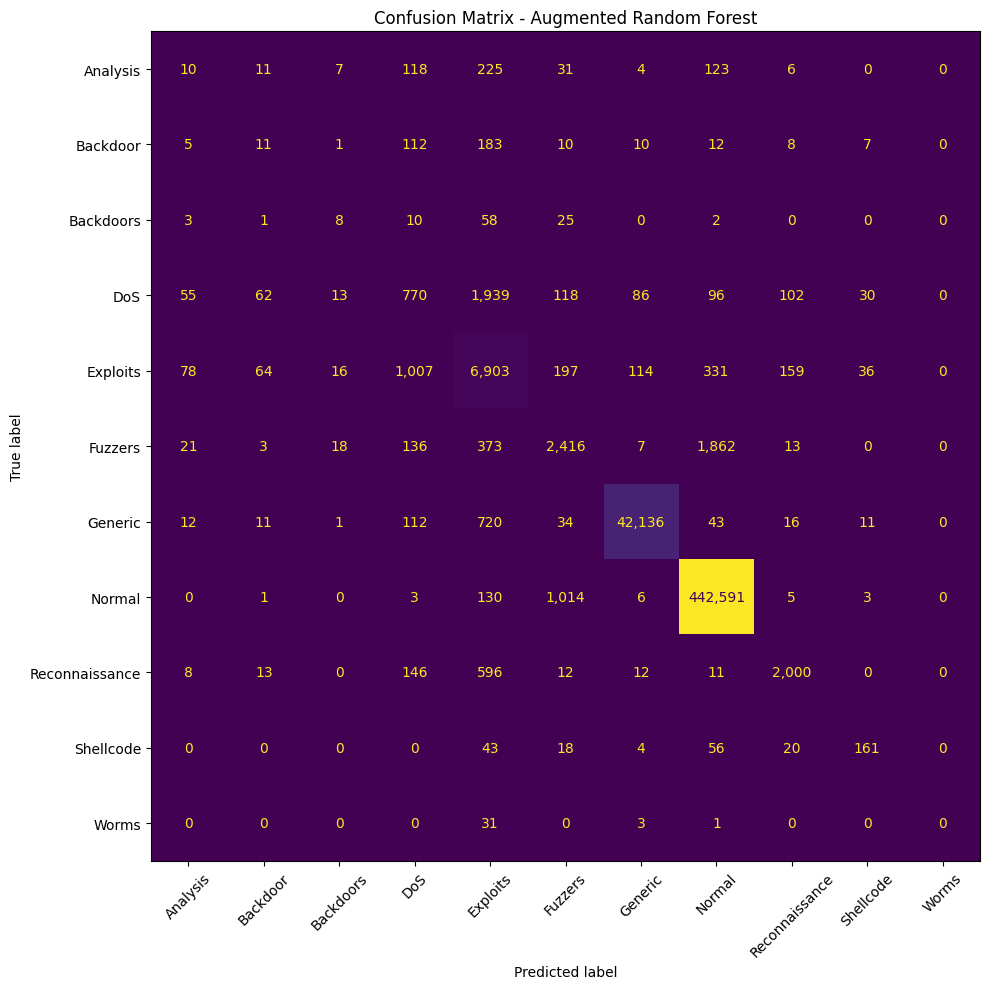

,Attack Category,Precision,Recall,F1 Score,Support
0,Analysis,0.0521,0.0187,0.0275,535
1,Backdoor,0.0621,0.0306,0.0410,359
2,Backdoors,0.1250,0.0748,0.0936,107
3,DoS,0.3190,0.2354,0.2709,3271
4,Exploits,0.6163,0.7752,0.6867,8905
5,Fuzzers,0.6235,0.4982,0.5539,4849
6,Generic,0.9942,0.9777,0.9859,43096
7,Normal,0.9943,0.9974,0.9958,443753
8,Reconnaissance,0.8587,0.7148,0.7802,2798
9,Shellcode,0.6492,0.5331,0.5855,302


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

# Compare baseline and augmented predictions
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_augmented_pred,
    labels=labels
)

fig, ax = plt.subplots(figsize=(12, 10))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(
    ax=ax,
    xticks_rotation=45,
    values_format=",",
    colorbar=False
)

plt.title("Confusion Matrix - Augmented Random Forest")
plt.tight_layout()
plt.show()

# Per-class precision, recall, and F1
precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_augmented_pred,
    labels=labels,
    zero_division=0
)

per_class_results = pd.DataFrame({
    "Attack Category": labels,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Support": support
})

display(per_class_results.round(4))

**Step 50 — Final baseline vs. augmented comparison**

In [63]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
import pandas as pd

# Baseline predictions were created earlier
# y_pred_baseline = predictions from the baseline sample_model

baseline_pred = sample_model.predict(X_test)

baseline_precision, baseline_recall, baseline_f1, _ = (
    precision_recall_fscore_support(
        y_test, baseline_pred,
        labels=labels, zero_division=0
    )
)

aug_precision, aug_recall, aug_f1, _ = (
    precision_recall_fscore_support(
        y_test, y_augmented_pred,
        labels=labels, zero_division=0
    )
)

comparison = pd.DataFrame({
    "Attack Category": labels,
    "Baseline F1": baseline_f1,
    "Augmented F1": aug_f1,
    "F1 Change": aug_f1 - baseline_f1
})

display(comparison.round(4))

summary = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Baseline": [
        accuracy_score(y_test, baseline_pred),
        f1_score(y_test, baseline_pred, average="macro", zero_division=0),
        f1_score(y_test, baseline_pred, average="weighted", zero_division=0)
    ],
    "Augmented": [
        accuracy_score(y_test, y_augmented_pred),
        f1_score(y_test, y_augmented_pred, average="macro", zero_division=0),
        f1_score(y_test, y_augmented_pred, average="weighted", zero_division=0)
    ]
})

summary["Change"] = summary["Augmented"] - summary["Baseline"]

print("\nOverall comparison:")
display(summary.round(4))

,Attack Category,Baseline F1,Augmented F1,F1 Change
0,Analysis,0.0225,0.0275,0.0050
1,Backdoor,0.0344,0.0410,0.0067
2,Backdoors,0.0698,0.0936,0.0238
3,DoS,0.2726,0.2709,-0.0017
4,Exploits,0.6841,0.6867,0.0025
5,Fuzzers,0.5444,0.5539,0.0095
6,Generic,0.9858,0.9859,0.0001
7,Normal,0.9957,0.9958,0.0001
8,Reconnaissance,0.7765,0.7802,0.0037
9,Shellcode,0.5313,0.5855,0.0541



Overall comparison:


,Metric,Baseline,Augmented,Change
0,Accuracy,0.9781,0.9783,0.0002
1,Macro F1,0.4470,0.4564,0.0094
2,Weighted F1,0.9770,0.9773,0.0003


In [64]:
import os
import joblib

os.makedirs("saved_models", exist_ok=True)

# Save the trained Random Forest pipeline
joblib.dump(
    augmented_model,
    "saved_models/augmented_model.joblib"
)

# Save the trained CTGAN generator
joblib.dump(
    ctgan_model_full,
    "saved_models/ctgan_model.joblib"
)

print("Models saved successfully!")
print("1. augmented_model.joblib")
print("2. ctgan_model.joblib")


Models saved successfully!
1. augmented_model.joblib
2. ctgan_model.joblib
